<a href="https://colab.research.google.com/github/AYUSH4951/DL_PROJECTS_AND-_NOTES/blob/main/cat_vs_dog_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#https://www.kaggle.com/datasets/razinw/dog-vs-cat

# NEED BIGGER DATASET FOR CORRECT PREDICTION OTHERWISE WRONG PREDICTION WILL COME AND THE DATASET WHICH I HAD USED DOESN'T HAVE SUFFICIENT DATA SO WORNG PREDICTION CAN COME

from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d razinw/dog-vs-cat
!unzip dog-vs-cat.zip

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/razinw/dog-vs-cat
License(s): unknown
100% 412M/412M [00:05<00:00, 84.5MB/s]

Archive:  dog-vs-cat.zip
  inflating: dogvscat/test/0/250.jpg  
  inflating: dogvscat/test/0/251.jpg  
  inflating: dogvscat/test/0/252.jpg  
  inflating: dogvscat/test/0/253.jpg  
  inflating: dogvscat/test/0/254.jpg  
  inflating: dogvscat/test/0/255.jpg  
  inflating: dogvscat/test/0/256.jpg  
  inflating: dogvscat/test/0/257.jpg  
  inflating: dogvscat/test/0/258.jpg  
  inflating: dogvscat/test/0/259.jpg  
  inflating: dogvscat/test/0/260.jpg  
  inflating: dogvscat/test/0/261.jpg  
  inflating: dogvscat/test/0/262.jpg  
  inflating: dogvscat/test/0/263.jpg  
  inflating: dogvscat/test/0/264.jpg  
  inflating: dogvscat/test/0/265.jpg  
  inflating: dogvscat/test/0/266.jpg  
  inflating: dogvscat/test/0/267.jpg  
  inflating: dogvscat/test/0/268.jpg  
  inflating: dogvscat/test/0/269.jpg  
  inflating: dogvscat/test/0/270.jpg  

In [ ]:
import zipfile

with zipfile.ZipFile('/content/dog-vs-cat.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dogs-vs-cats')

print("Extraction completed!")

Extraction completed!


In [ ]:
import shutil

shutil.rmtree('/content/dogs-vs-cats')

print("Folder deleted successfully!")


Folder deleted successfully!


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, BatchNormalization, Dropout

In [ ]:
#generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/dogvscat/train',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256, 256)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/dogvscat/test',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256, 256)
)

Found 500 files belonging to 2 classes.
Found 50 files belonging to 2 classes.


In [ ]:
# Normalize
def process(image,label):
  image = tf.cast(image/255. ,tf.float32)
  return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [ ]:
# Create CNN Model

model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history = model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 30s 954ms/step - accuracy: 0.5140 - loss: 7.8791 - val_accuracy: 0.4400 - val_loss: 1.2296
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 444ms/step - accuracy: 0.6040 - loss: 4.6207 - val_accuracy: 0.5000 - val_loss: 5.4812
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 476ms/step - accuracy: 0.6740 - loss: 2.8913 - val_accuracy: 0.6200 - val_loss: 3.0828
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 411ms/step - accuracy: 0.7440 - loss: 2.5931 - val_accuracy: 0.5800 - val_loss: 5.2151
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 447ms/step - accuracy: 0.7560 - loss: 2.4534 - val_accuracy: 0.5000 - val_loss: 10.2043
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 481ms/step - accuracy: 0.7760 - loss: 1.7568 - val_accuracy: 0.5000 - val_loss: 17.4386
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 459ms/step - accuracy: 0.7820 - loss: 2.1276 - val_accuracy: 0.5200 - val_loss: 8.6222
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 404ms/step - accuracy: 0.8300 - loss: 1.4010 - val_accuracy

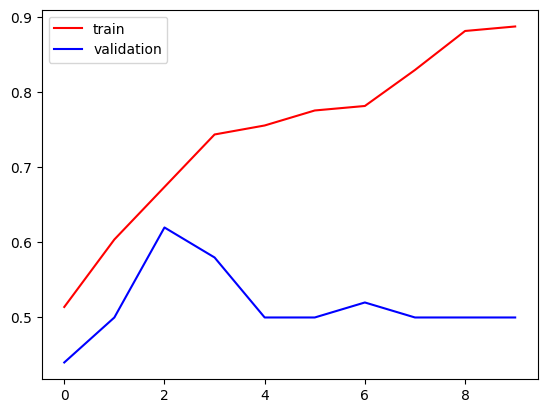

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
import cv2

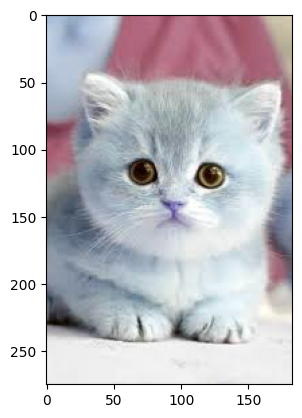

In [ ]:
test_img = cv2.imread('/content/cats.jpg')
plt.imshow(test_img)

In [ ]:
test_img.shape

(275, 183, 3)

In [ ]:
test_img = cv2.resize(test_img,(256,256))

In [ ]:
test_input = test_img.reshape((1,256,256,3))

In [ ]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([[0.]], dtype=float32)

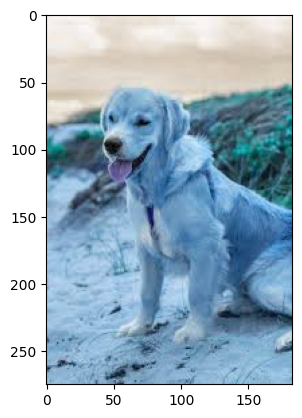

In [ ]:
test_img = cv2.imread('/content/dog.jpg')
plt.imshow(test_img)


In [ ]:


test_img.shape


(275, 183, 3)

In [ ]:
test_img = cv2.resize(test_img,(256,256))


In [ ]:
test_input = test_img.reshape((1,256,256,3))


In [ ]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


array([[0.]], dtype=float32)

In [ ]:
from keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
batch_size = 16
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/dogvscat/train',
    target_size=(256, 256),
    batch_size=batch_size,
    class_mode='binary'
)

Found 500 images belonging to 2 classes.


In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Activation

model = Sequential()
model.add(Conv2D(32, (3, 3), input_shape=(256, 256, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(32, (3, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.add(Flatten())
model.add(Dense(64))
model.add(Activation('relu'))
model.add(Dropout(0.5))
model.add(Dense(1))
model.add(Activation('sigmoid'))

model.compile(
    loss='binary_crossentropy',
    optimizer='rmsprop',
    metrics=['accuracy']
)

In [ ]:
model.fit(
    train_generator,
    steps_per_epoch=2000 // batch_size,
    epochs=25,
    validation_data=validation_ds,
    validation_steps=800 // batch_size
)

Epoch 1/25
 32/125 ━━━━━━━━━━━━━━━━━━━━ 54s 586ms/step - accuracy: 0.5443 - loss: 0.8084

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


125/125 ━━━━━━━━━━━━━━━━━━━━ 27s 165ms/step - accuracy: 0.5340 - loss: 0.7438 - val_accuracy: 0.5600 - val_loss: 0.6924
Epoch 2/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - accuracy: 0.4880 - loss: 0.6929 - val_accuracy: 0.5000 - val_loss: 0.6978
Epoch 3/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 136ms/step - accuracy: 0.5100 - loss: 0.7647 - val_accuracy: 0.5800 - val_loss: 0.6791
Epoch 4/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 131ms/step - accuracy: 0.5480 - loss: 0.6849 - val_accuracy: 0.5200 - val_loss: 0.6700
Epoch 5/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 136ms/step - accuracy: 0.5400 - loss: 0.6969 - val_accuracy: 0.5000 - val_loss: 0.6773
Epoch 6/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - accuracy: 0.5720 - loss: 0.6893 - val_accuracy: 0.6000 - val_loss: 0.6723
Epoch 7/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - accuracy: 0.5860 - loss: 0.6889 - val_accuracy: 0.5200 - val_loss: 0.6673
Epoch 8/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 137ms/step - accuracy: 0.6040 - loss: 0.6715 - val

In [ ]:
print(model.input_shape)

(None, 256, 256, 3)


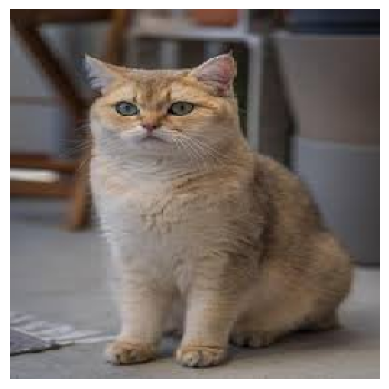

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Raw Prediction: [[0.65729463]]
Prediction: Dog 🐶


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

img_path = "/content/cat.jpg"  # Your image path

img = image.load_img(img_path, target_size=(256, 256))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

plt.imshow(img)
plt.axis("off")
plt.show()

prediction = model.predict(img_array)

print("Raw Prediction:", prediction)

if prediction[0][0] > 0.5:
    print("Prediction: Dog 🐶")
else:
    print("Prediction: Cat 🐱")